In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

In [65]:
import numpy as np
import pandas as pd
import os
import seaborn as sns
from tqdm import tqdm
import matplotlib.pyplot as plt
import xgboost, lightgbm, catboost

from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import ParameterGrid
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import config as cnf 
import utils as utl
import DeepLearning as DL

In [ ]:
EPOCHS = 100
loss_model = nn.CrossEntropyLoss() 
df_train = pd.read_csv(cnf.path['train_path'])

# Обработка данных
df_train_priz = df_train[['Survived', 'Pclass', 'Age', 'Sex',  'SibSp', 'Parch', 'Fare', 'Embarked']].copy()
df_train_priz['Age'] = df_train_priz['Age'].fillna(df_train_priz['Age'].median())
df_train_priz['Embarked'] = df_train_priz['Embarked'].fillna('S')

for col in ['Sex', 'Embarked']:
    df_train_priz[col] = df_train_priz[col].astype('category')

X = df_train_priz.drop('Survived', axis=1)
X = pd.get_dummies(X, dtype=float, drop_first=True)
y = df_train_priz['Survived']

results = []
SK_Fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=cnf.random_state)


for i, (train_index, test_index) in enumerate(SK_Fold.split(X, y)):
    
    torch.manual_seed(cnf.random_state)
    model = DL.nn_model(X.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=5, threshold=1e-2)
    
    current_X_train = X.iloc[train_index]
    current_y_train = y.iloc[train_index]
    current_X_test  = X.iloc[test_index]
    current_y_test  = y.iloc[test_index]
    
    scaler = StandardScaler()
    scaler.fit(current_X_train)
    current_X_train = scaler.transform(current_X_train)
    current_X_test = scaler.transform(current_X_test)
    
    tensor_current_X_train = torch.tensor(current_X_train, dtype=torch.float32)
    tensor_current_X_test  = torch.tensor(current_X_test,  dtype=torch.float32)
    tensor_current_y_train = torch.tensor(current_y_train.values, dtype=torch.long)
    tensor_current_y_test  = torch.tensor(current_y_test.values,  dtype=torch.long)
    
    dataset = TensorDataset(tensor_current_X_train, tensor_current_y_train)
    dataloader = DataLoader(dataset, batch_size=64, shuffle=True, drop_last=True)
    
    train_loop = tqdm(range(EPOCHS))   
    for epoch in train_loop:
        
        model.train()

        for _, val in enumerate(dataloader):

            # Прямой проход
            pred = model(val[0])
            loss = loss_model(pred, val[1])

            # Обратный проход
            opt.zero_grad()
            loss.backward()

            # Шаг оптимизации
            opt.step()
        
        model.eval()

        # Считаем на валидации
        with torch.no_grad():

            # Считаем предсказания
            pred_train = model(tensor_current_X_train)
            pred_test = model(tensor_current_X_test)

            # Считаем лосс
            loss_train = loss_model(pred_train, tensor_current_y_train)
            loss_test = loss_model(pred_test, tensor_current_y_test)

            # Считаем точность на трейне
            train_loss = loss_train.item()
            true_answer = (pred_train.argmax(dim=1) == tensor_current_y_train).sum().item()
            train_accuracy = true_answer / len(tensor_current_X_train)

            # Считаем точность на тесте
            test_loss = loss_test.item()
            true_answer = (pred_test.argmax(dim=1) == tensor_current_y_test).sum().item()
            test_accuracy = true_answer / len(tensor_current_X_test)

        train_loop.set_description(f"Epoch [{epoch+1}/{EPOCHS}], train_loss={train_loss:2f}, train_accuracy={train_accuracy:2f}, test_loss={test_loss:2f} test_accuracy={test_accuracy:2f} lr={scheduler.get_last_lr()[0]}")

        scheduler.step(train_loss)

        results.append({
            'Fold'              :   i
            , 'epoch'           :   epoch
            , 'train_accuracy'  :   train_accuracy
            , 'train_loss'      :   train_loss
            , 'test_accuracy'   :   test_accuracy
            , 'test_loss'       :   test_loss
            , 'lr'              :   opt.param_groups[0]['lr']
        })

Epoch [100/100], train_loss=0.293555, train_accuracy=0.872191, test_loss=0.445124 test_accuracy=0.821229 lr=1.5625e-05: 100%|██████████| 100/100 [00:07<00:00, 14.08it/s]
Epoch [100/100], train_loss=0.281204, train_accuracy=0.882188, test_loss=0.430332 test_accuracy=0.820225 lr=3.125e-05: 100%|██████████| 100/100 [00:06<00:00, 14.37it/s]
Epoch [100/100], train_loss=0.261536, train_accuracy=0.892006, test_loss=0.547266 test_accuracy=0.786517 lr=6.25e-05: 100%|██████████| 100/100 [00:06<00:00, 14.76it/s]
Epoch [100/100], train_loss=0.291893, train_accuracy=0.873773, test_loss=0.421379 test_accuracy=0.842697 lr=3.125e-05: 100%|██████████| 100/100 [00:06<00:00, 14.63it/s]
Epoch [100/100], train_loss=0.296571, train_accuracy=0.875175, test_loss=0.495372 test_accuracy=0.803371 lr=3.90625e-06: 100%|██████████| 100/100 [00:06<00:00, 14.55it/s]


In [68]:
results = pd.DataFrame(results)
results

,Fold,epoch,train_accuracy,train_loss,test_accuracy,test_loss,lr
0,0,0,0.827247,0.561024,0.776536,0.562910,0.001000
1,0,1,0.827247,0.418421,0.843575,0.425232,0.001000
2,0,2,0.839888,0.389716,0.860335,0.395440,0.001000
3,0,3,0.837079,0.393942,0.860335,0.402530,0.001000
4,0,4,0.844101,0.381805,0.843575,0.396396,0.001000
...,...,...,...,...,...,...,...
495,4,95,0.875175,0.295903,0.814607,0.499002,0.000004
496,4,96,0.876578,0.296238,0.808989,0.497058,0.000004
497,4,97,0.875175,0.296121,0.814607,0.498595,0.000004
498,4,98,0.875175,0.296509,0.820225,0.495885,0.000004


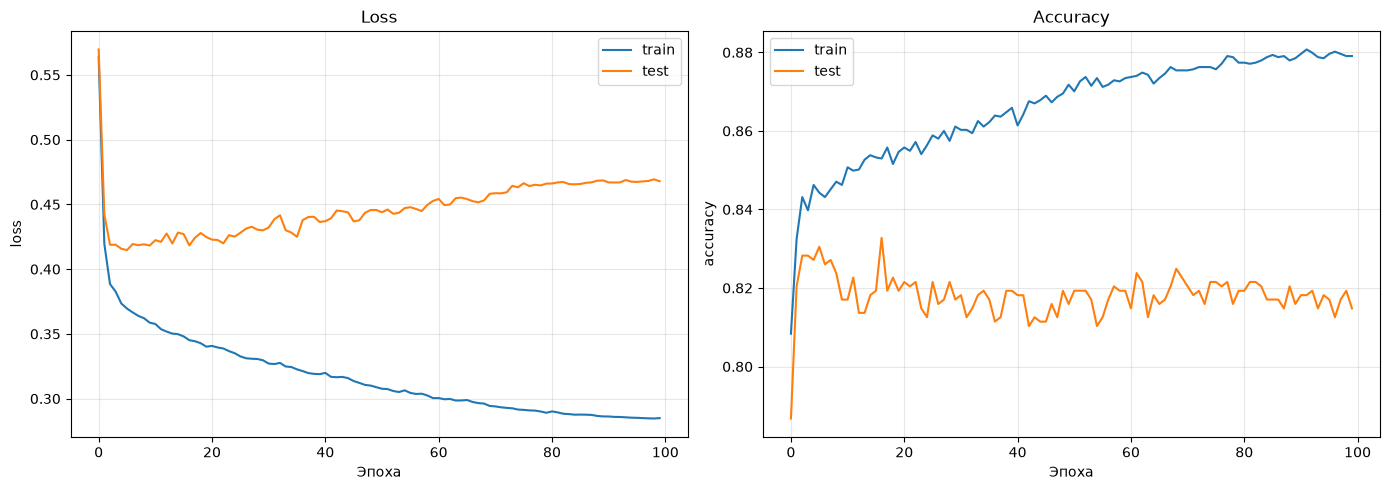

In [69]:
# усредняем по фолдам (для одного фолда значения просто остаются как есть)
curve = results.groupby('epoch').mean(numeric_only=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(curve.index, curve['train_loss'], label='train')
axes[0].plot(curve.index, curve['test_loss'],  label='test')
axes[0].set_title('Loss')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(curve.index, curve['train_accuracy'], label='train')
axes[1].plot(curve.index, curve['test_accuracy'],  label='test')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()